# Part 2: Language classification with hyperdimensional vectors

This notebook uses 3-grams and random +1/-1 hypervectors to recognize 21 European languages.

In [50]:
import glob
import re
import random
from pathlib import Path
from itertools import islice
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay

## Task 2.1: Importing and preprocessing the data

For each language, the News Wortschatz sentence file is cleaned and split into training (70%), validation (15%), and test (15%) sets. The split uses a fixed random seed so it can be reproduced. Europarl is kept separate for final testing.

In [51]:
PART2_DIR = Path.cwd()
if not (PART2_DIR / "News Wortschatz Corpora Dataset").is_dir():
    PART2_DIR = PART2_DIR / "Part2"

DATA_DIR = PART2_DIR / "News Wortschatz Corpora Dataset"
EUROPARL_DIR = PART2_DIR / "EuroDataset"
DIMENSIONS = (100, 1000)

languages = {
    "bul": ("Bulgarian", "bg"), "ces": ("Czech", "cs"), "dan": ("Danish", "da"),
    "deu": ("German", "de"), "ell": ("Greek", "el"), "eng": ("English", "en"),
    "est": ("Estonian", "et"), "fin": ("Finnish", "fi"), "fra": ("French", "fr"),
    "hun": ("Hungarian", "hu"), "ita": ("Italian", "it"), "lav": ("Latvian", "lv"),
    "lit": ("Lithuanian", "lt"), "nld": ("Dutch", "nl"), "pol": ("Polish", "pl"),
    "por": ("Portuguese", "pt"), "ron": ("Romanian", "ro"), "slk": ("Slovak", "sk"),
    "slv": ("Slovene", "sl"), "spa": ("Spanish", "es"), "swe": ("Swedish", "sv"),
}
labels = [name for name, _ in languages.values()]

In [52]:
def clean_text(text):
    # keep letters of any alphabet in lowercase, replace punctuation and digits with spaces,
    # then collapse repeated spaces so no fake trigrams like "  a" appear
    text = "".join(ch.lower() if ch.isalpha() else " " for ch in text)
    return re.sub(r"\s+", " ", text).strip()

def read_sentences(code):
    path = glob.glob(str(DATA_DIR / f"{code}_news_*" / "*-sentences.txt"))[0]
    with open(path, encoding="utf-8") as file:
        texts = [clean_text(line.split("\t", 1)[1]) for line in file]   # drop the id column
    return [t for t in texts if t]   # remove sentences that are empty after cleaning


train_texts, train_labels = [], []
val_texts, val_labels = [], []
test_texts, test_labels = [], []

for code, (name, _) in languages.items():
    texts = read_sentences(code)
    print(f"{name:11} {len(texts)} sentences, average {np.mean([len(t) for t in texts]):.0f} characters")

    # shuffle with a fixed seed so the split is random but the same on every run
    random.Random(42).shuffle(texts)

    # split each language separately (70/15/15) so every language has the same share in each set
    n_train, n_val = int(0.70 * len(texts)), int(0.15 * len(texts))
    train_texts += texts[:n_train]
    val_texts += texts[n_train:n_train + n_val]
    test_texts += texts[n_train + n_val:]
    train_labels += [name] * n_train
    val_labels += [name] * n_val
    test_labels += [name] * (len(texts) - n_train - n_val)

print(len(train_texts), len(val_texts), len(test_texts))

Bulgarian   10000 sentences, average 105 characters
Czech       10000 sentences, average 95 characters
Danish      10000 sentences, average 101 characters
German      10000 sentences, average 103 characters
Greek       10000 sentences, average 123 characters
English     10000 sentences, average 113 characters
Estonian    10000 sentences, average 103 characters
Finnish     10000 sentences, average 96 characters
French      10000 sentences, average 117 characters
Hungarian   10000 sentences, average 122 characters
Italian     10000 sentences, average 118 characters
Latvian     10000 sentences, average 118 characters
Lithuanian  10000 sentences, average 105 characters
Dutch       10000 sentences, average 87 characters
Polish      10000 sentences, average 93 characters
Portuguese  10000 sentences, average 116 characters
Romanian    10000 sentences, average 111 characters
Slovak      10000 sentences, average 99 characters
Slovene     10000 sentences, average 110 characters
Spanish     10000

In [53]:
# Europarl for the final test: EuroDataset/bg-en/europarl-v7.bg-en.bg etc., one sentence per line
# English has no pair of its own, so it is read from the bg-en folder
def read_europarl(n=1000, max_lines=10000):
    texts, true_labels = [], []
    for name, euro_code in languages.values():
        pair = "bg" if euro_code == "en" else euro_code
        path = EUROPARL_DIR / f"{pair}-en" / f"europarl-v7.{pair}-en.{euro_code}"
        with open(path, encoding="utf-8") as file:
            lines = [clean_text(line) for line in islice(file, max_lines)]   # files are huge, the start is enough
        # skip empty lines and short fragments, then pick n random sentences
        lines = random.Random(42).sample([line for line in lines if len(line) > 20], n)
        texts += lines
        true_labels += [name] * n
    return texts, true_labels


euro_texts, euro_labels = read_europarl()
print(len(euro_texts))
print(euro_labels[0], "|", euro_texts[0])

21000
Bulgarian | дневен ред на следващото заседание вж протокола


## Task 2.2: Constructing high-dimensional centroids

Following the article: every symbol gets a random +1/-1 vector (item memory). The symbol in position j of a trigram is permuted j times (ρʲ, a cyclic shift) and the three vectors are bound by elementwise multiplication, eq. (4). A text vector is the sum of its trigram vectors, each weighted by how often the trigram occurs, eq. (5). Training adds the text vectors of each language into one centroid per language: shape (21, 100) or (21, 1000).

In [54]:
rng = np.random.default_rng(42)
letter_vecs = {}   # item memory: one random +1/-1 vector per symbol and dimension

def letter_vector(ch, dimension):
    if (ch, dimension) not in letter_vecs:
        letter_vecs[(ch, dimension)] = rng.choice([-1, 1], dimension)
    return letter_vecs[(ch, dimension)]


def trigram_vector(trigram, dimension):
    # eq. (4): the symbol in position j is shifted j times, then the three vectors are multiplied
    # the shifts keep the order, so "abc" and "cba" get different vectors
    a, b, c = (letter_vector(ch, dimension) for ch in trigram)
    return np.roll(a, 1) * np.roll(b, 2) * np.roll(c, 3)


def encode(text, dimension, cache):
    # eq. (5): count the trigrams first, then add each distinct trigram vector times its count
    counts = Counter(text[i:i + 3] for i in range(len(text) - 2))
    result = np.zeros(dimension)
    for trigram, count in counts.items():
        if trigram not in cache:
            cache[trigram] = trigram_vector(trigram, dimension)
        result += count * cache[trigram]
    return result

In [55]:
# one centroid per language, trained once for each dimension and reused for every evaluation
centroids, caches = {}, {}

for dimension in DIMENSIONS:
    caches[dimension] = {}
    centroids[dimension] = np.zeros((len(labels), dimension))
    for text, label in zip(train_texts, train_labels):
        centroids[dimension][labels.index(label)] += encode(text, dimension, caches[dimension])
    print(dimension, centroids[dimension].shape)

# numbers for Q1: alphabet size, size of the local trigram vector, and how many trigrams really occur
alphabet = set("".join(train_texts))
print("alphabet size A:", len(alphabet))
print("local trigram vector size A^3:", len(alphabet) ** 3)
print("distinct trigrams in training:", len(caches[1000]))

100 (21, 100)
1000 (21, 1000)
alphabet size A: 192
local trigram vector size A^3: 7077888
distinct trigrams in training: 62364


**Q1: What is the size of the n-gram input vector in conventional (local) representation?**

A local representation has one position for every possible n-gram, so its size is aⁿ for an alphabet of a symbols. For trigrams this is a³.
The article maps all text to the 26 Latin letters plus space (a = 27), giving 27³ = 19,683.
We keep all letters of the 21 languages (Greek, Cyrillic, accented letters), so a and a³ are much larger; see the output above.

**Q2: Difficulties of working with conventional n-gram representations in machine learning**

- The size grows exponentially with n (aⁿ), so it becomes huge for larger n or bigger alphabets.
- The vectors are very sparse: only a small part of all possible trigrams ever occurs (see the output above), which wastes memory and computation.
- Sparse storage only helps on the input side: a model such as a SOM or a centroid classifier has dense weight vectors, so distances still need all aⁿ positions.
- The size depends on the alphabet and must be fixed in advance; a new symbol changes the whole representation.
- Many features compared to the amount of training data make learning slow and prone to overfitting.

With the HD mapping the vector length d is chosen freely (100 or 1000) and does not depend on a or n.

## Task 2.3: Classification using hyperdimensional centroids

For each query, build its trigram vector, compare it with all 21 centroids using cosine similarity, and select the language with the highest score. Accuracy, macro-F1, and confusion matrices are reported for validation, News test, and Europarl test data. Macro-F1 gives each language equal weight.

In [56]:
def evaluate(dimension, texts, true_labels, title):
    queries = np.array([encode(t, dimension, caches[dimension]) for t in texts])
    # cosine similarity: normalising the centroids is enough, the query norm doesn't change which one is highest
    C = centroids[dimension] / np.linalg.norm(centroids[dimension], axis=1, keepdims=True)
    # NumPy 2 on macOS reports false floating-point warnings in matmul, so they are silenced here
    with np.errstate(divide="ignore", over="ignore", invalid="ignore"):
        similarities = queries @ C.T
    predictions = [labels[i] for i in np.argmax(similarities, axis=1)]

    accuracy = accuracy_score(true_labels, predictions)
    f1 = f1_score(true_labels, predictions, average="macro")
    print(f"{title}: accuracy={accuracy:.4f}, macro-F1={f1:.4f}")

    fig, ax = plt.subplots(figsize=(12, 12))
    ConfusionMatrixDisplay.from_predictions(true_labels, predictions, labels=labels, ax=ax,
                                            xticks_rotation=90, colorbar=False)
    ax.set_title(title)
    plt.tight_layout()
    plt.show()

News validation (d=100): accuracy=0.6926, macro-F1=0.6896


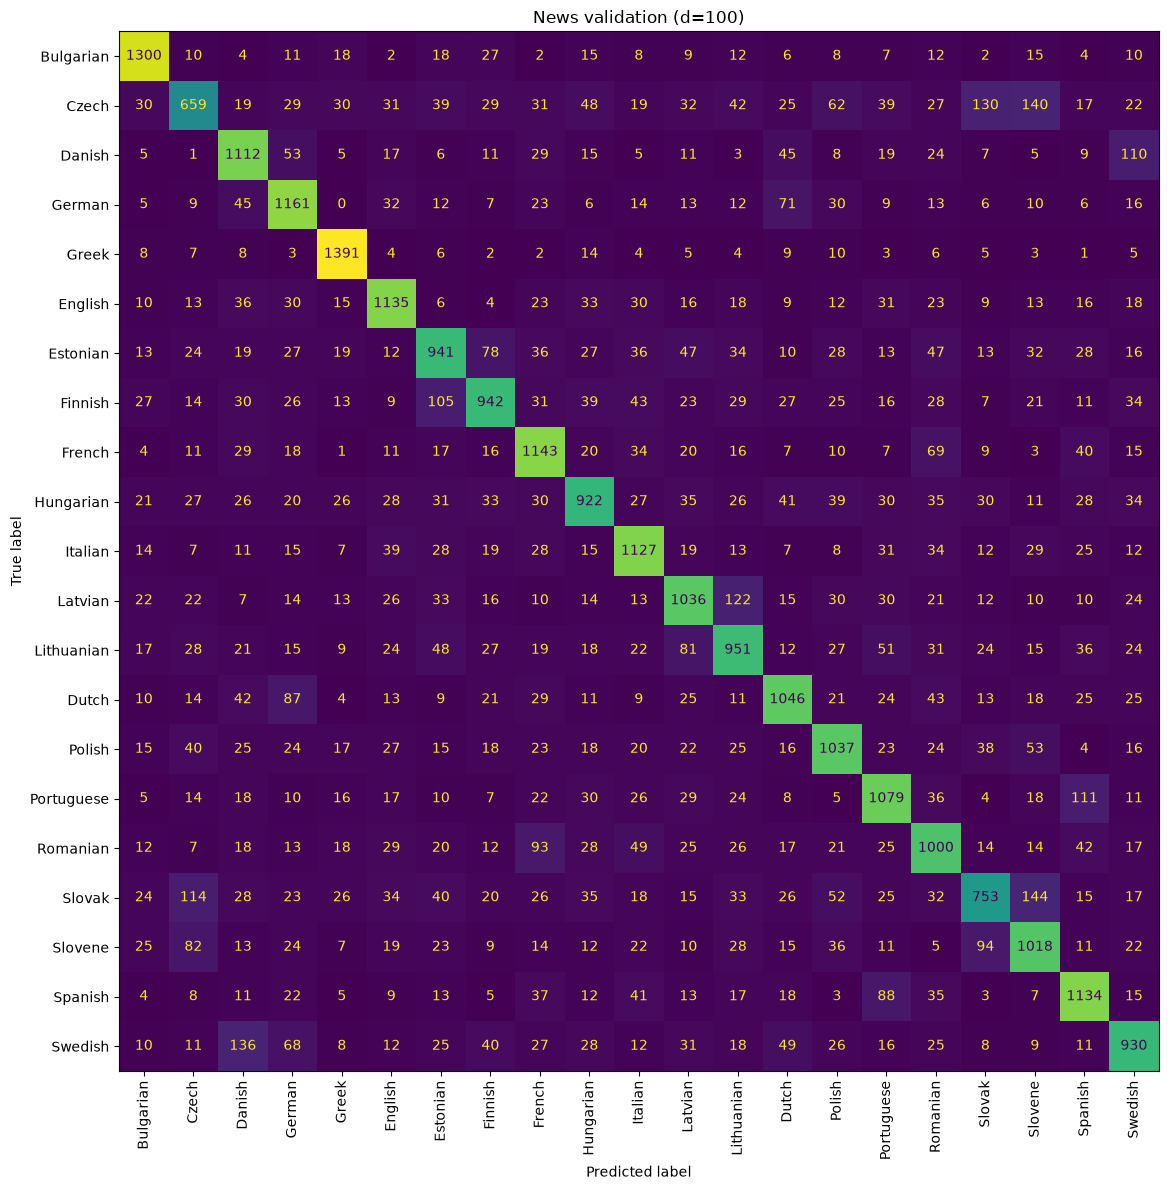

News test (d=100): accuracy=0.6938, macro-F1=0.6909


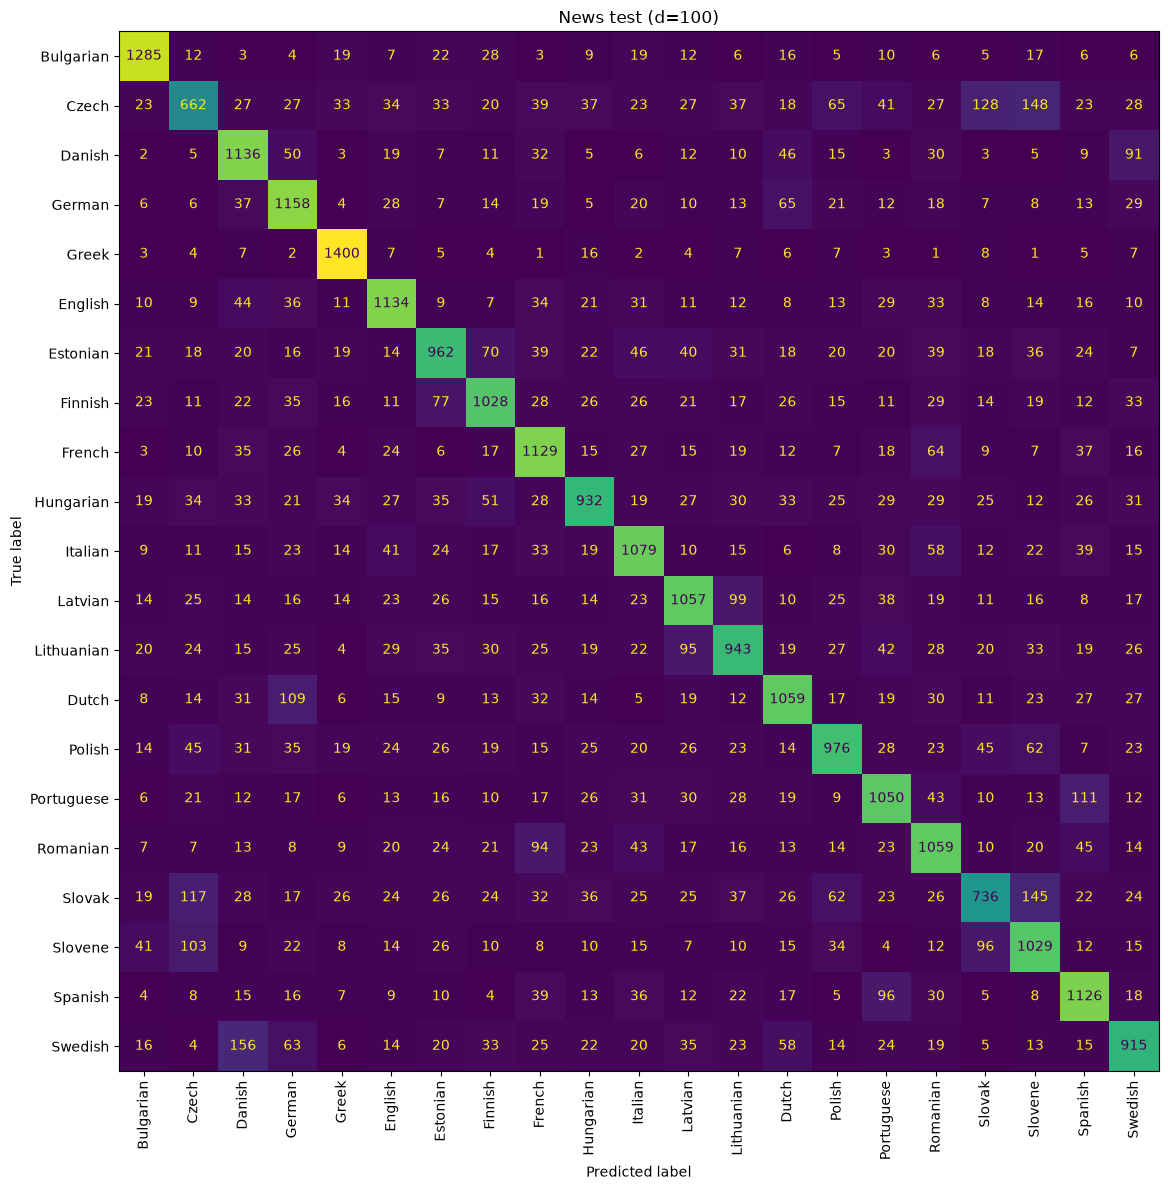

Europarl final test (d=100): accuracy=0.7495, macro-F1=0.7470


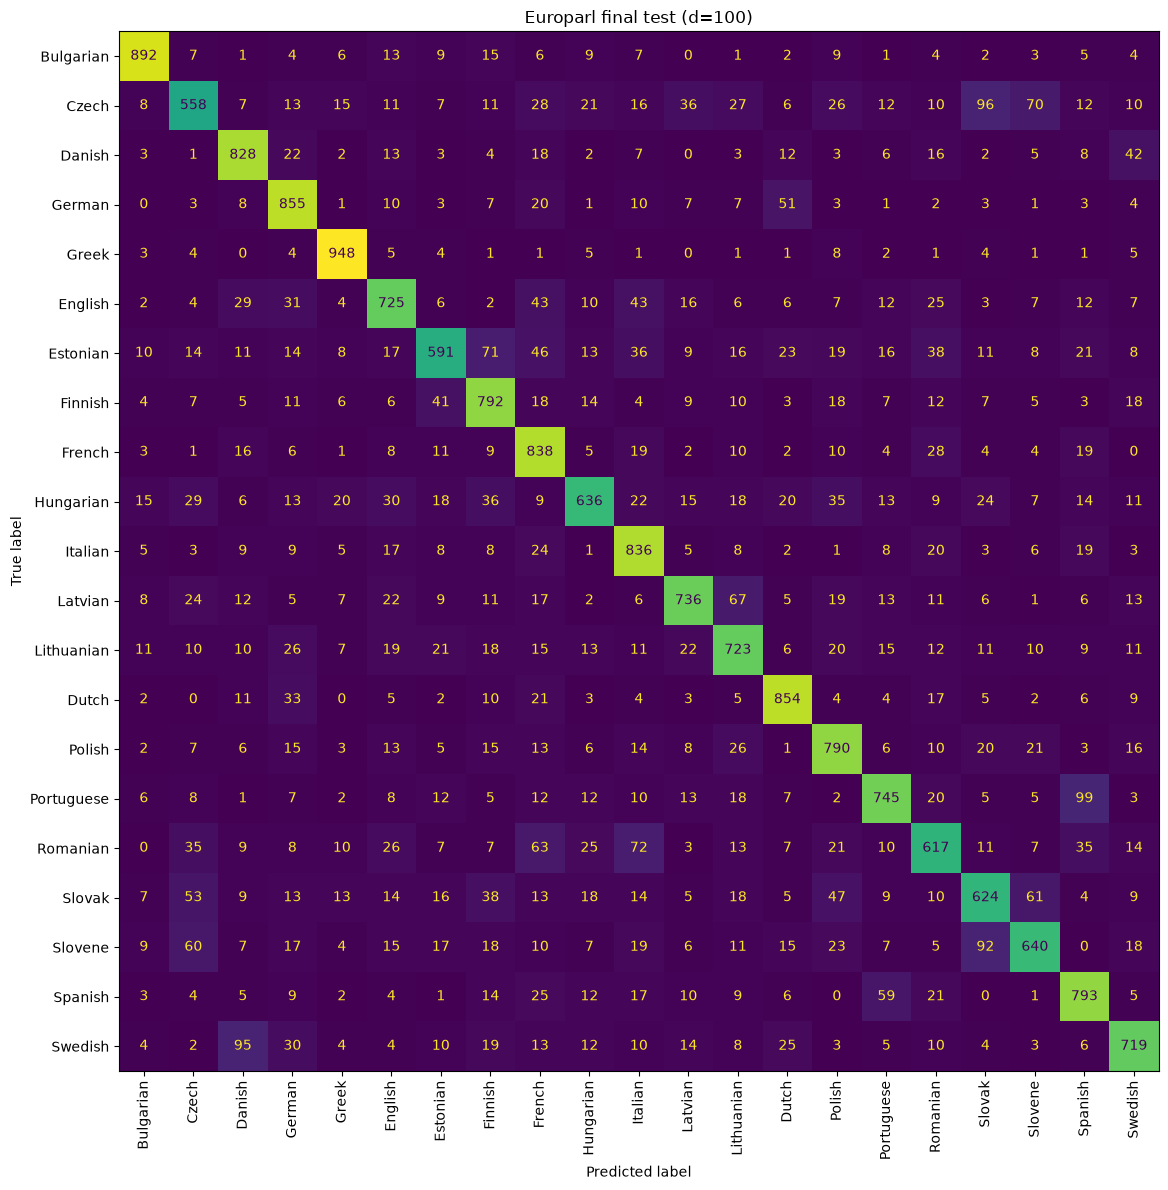

News validation (d=1000): accuracy=0.9492, macro-F1=0.9492


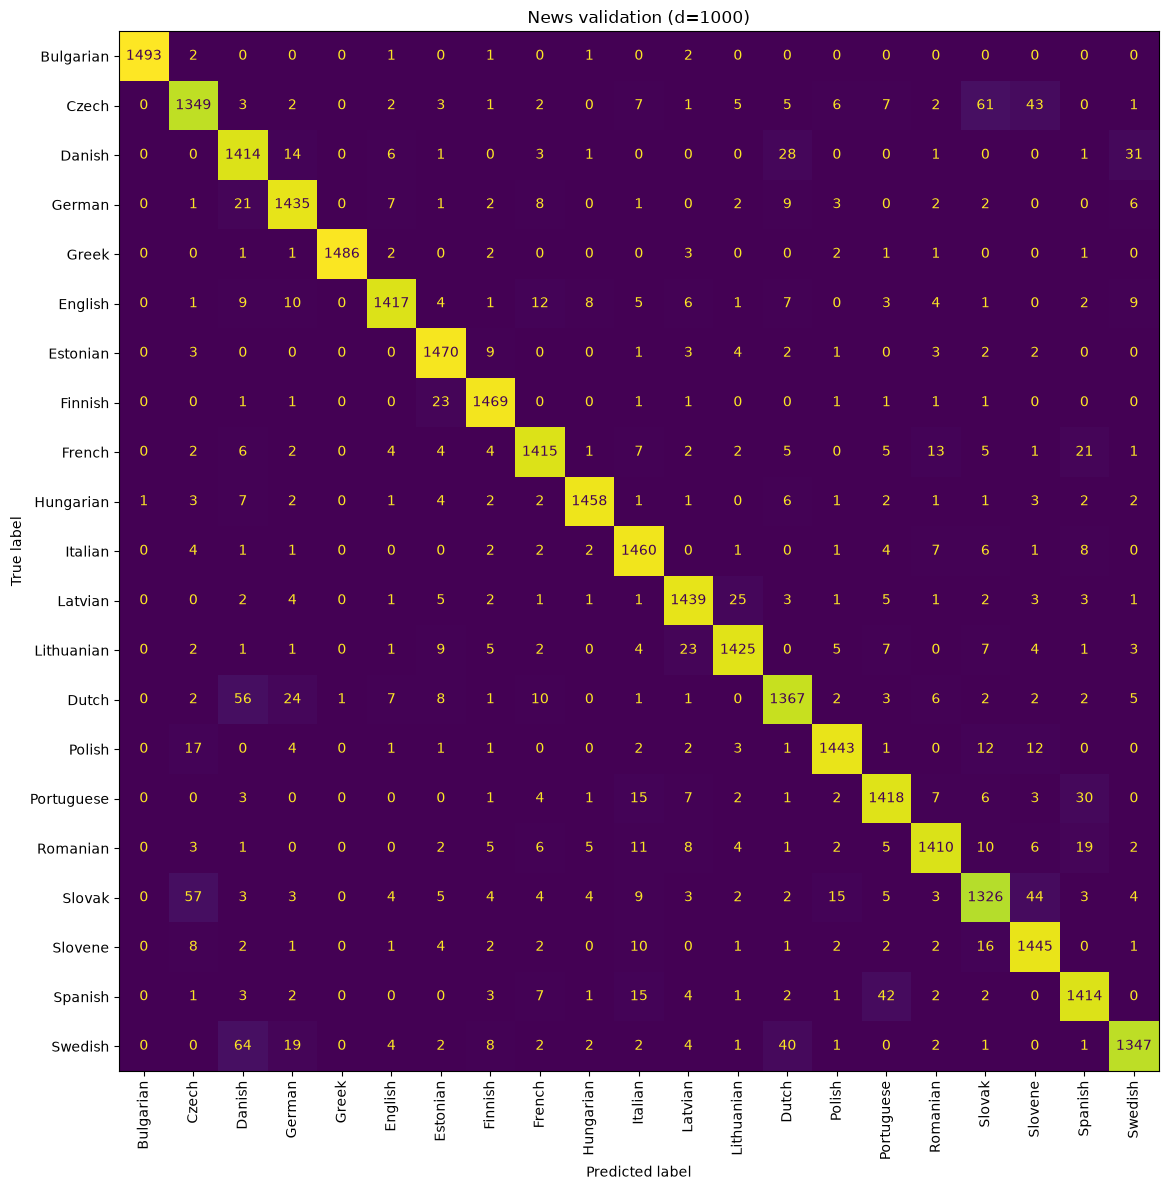

News test (d=1000): accuracy=0.9510, macro-F1=0.9510


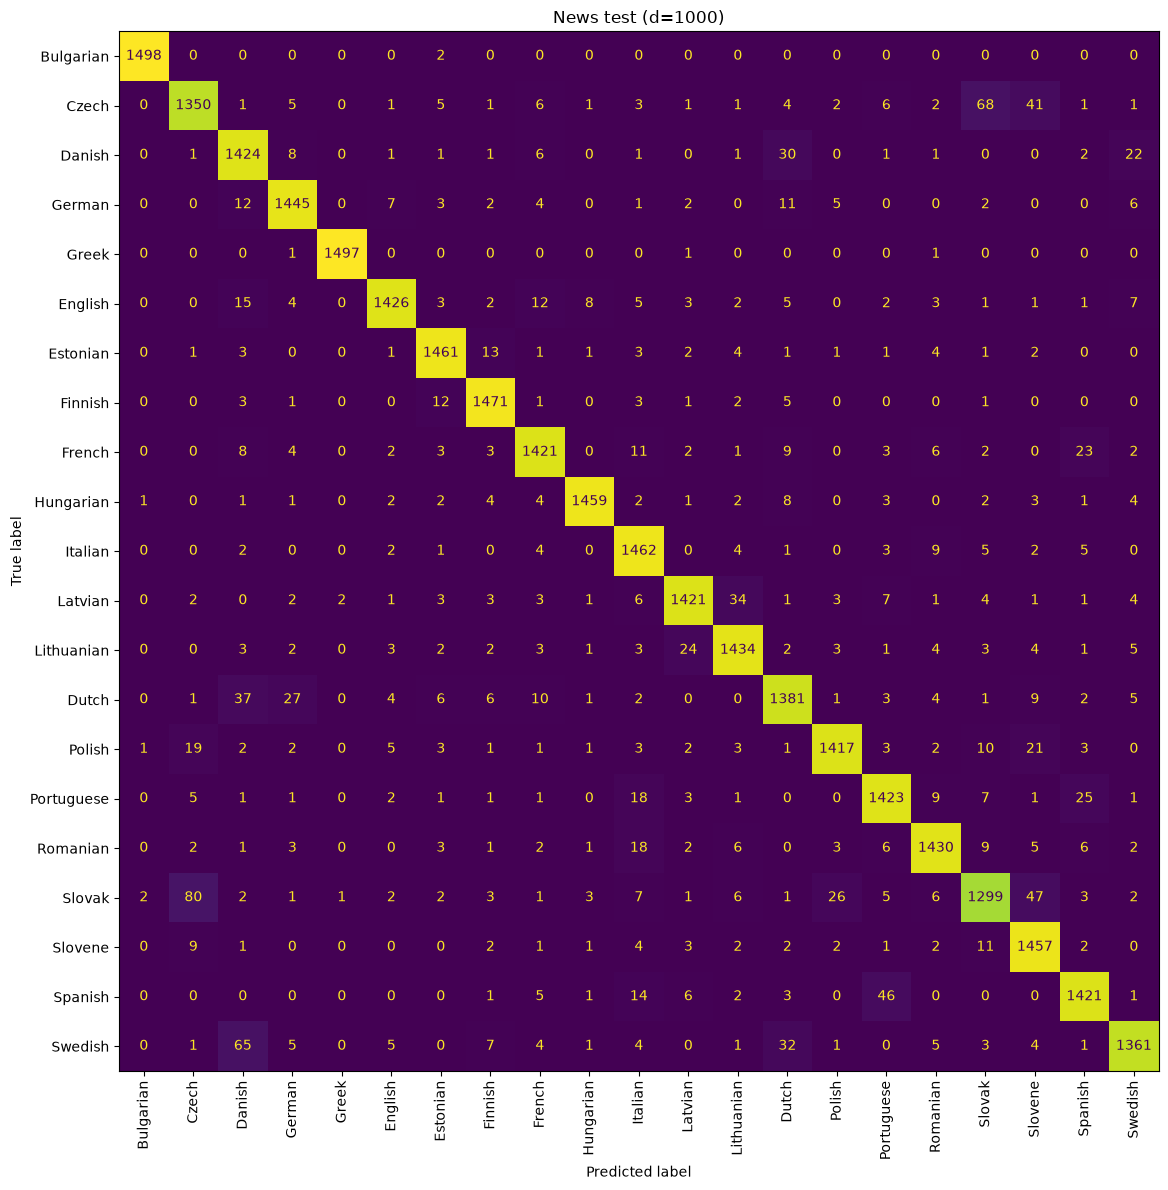

Europarl final test (d=1000): accuracy=0.9490, macro-F1=0.9490


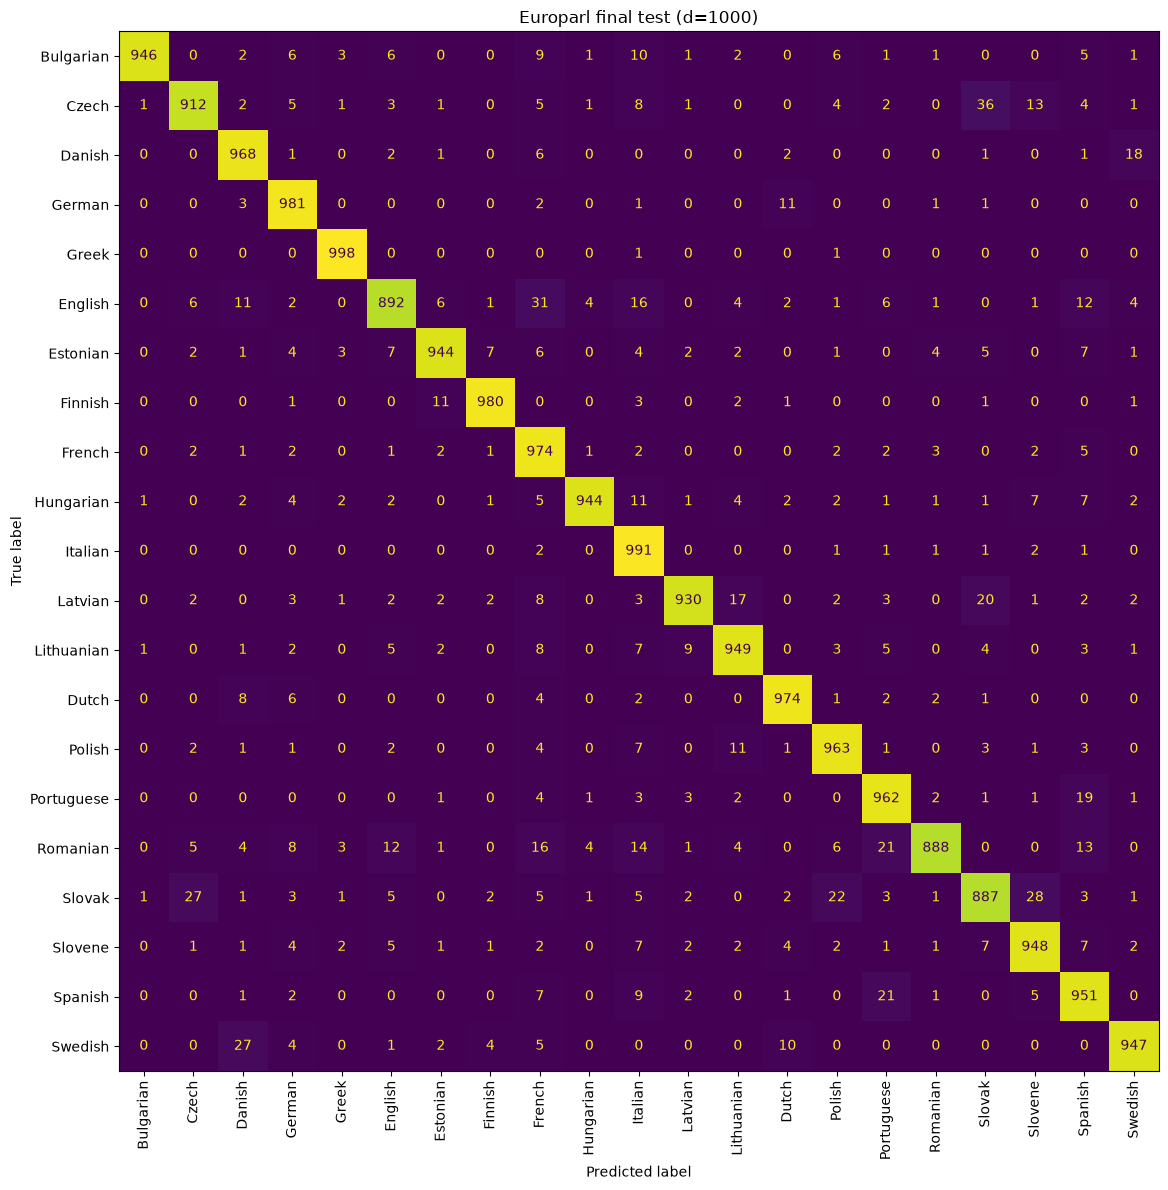

In [57]:
# validation and test on News Wortschatz, final test on Europarl
for dimension in DIMENSIONS:
    evaluate(dimension, val_texts, val_labels, f"News validation (d={dimension})")
    evaluate(dimension, test_texts, test_labels, f"News test (d={dimension})")
    evaluate(dimension, euro_texts, euro_labels, f"Europarl final test (d={dimension})")